# 03 — World-line preview (illustrative only)

**Status: `ILLUSTRATIVE PREVIEW - NOT VALIDATED`.** This is a communication and debugging artifact, not a result. It is read-only and CPU only; no fitting.

- **Two steps only.** Step 1 is sampled from the frozen one-step model. Step 2 uses a **state-lag-only approximation**, not a generative feature model.
- **No multi-step accuracy claim.** No test labels are read and no accuracy is computed.
- **Actor states are projections.** Node cells count active sampled dyads, not full-network activity. They are not node-level predictions.
- **Deletable.** Removing this preview does not affect any main result, table, figure, or abstract sentence.


In [1]:
from pathlib import Path
import json

import pandas as pd

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

try:
    from IPython.display import display
except Exception:
    display = print


def find_repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in (here, *here.parents):
        if (cand / "results" / "framework_pilot").is_dir():
            return cand
    return here


ROOT = find_repo_root()
WORLDLINE = ROOT / "results" / "worldline_preview"


def rel(path: Path) -> str:
    try:
        return str(path.relative_to(ROOT))
    except ValueError:
        return str(path)


def load_json(path: Path) -> dict:
    if not path.is_file():
        print(f"[missing] {rel(path)}")
        return {}
    with path.open(encoding="utf-8") as fh:
        return json.load(fh)


def load_csv(path: Path) -> pd.DataFrame:
    if not path.is_file():
        print(f"[missing] {rel(path)}")
        return pd.DataFrame()
    return pd.read_csv(path)


print("repo root:", rel(ROOT))
print("worldline artifacts:", "present" if WORLDLINE.is_dir() else "MISSING")


repo root: .
worldline artifacts: present


## Anchor summary

Four anchors from the inner-validation period (2016-01 to 2017-11). The sample is selected for visibility, not random: five source actors at evenly spaced activity ranks, with a small set of active and inactive dyads per source.


In [2]:
meta = load_json(WORLDLINE / "worldline_trace.json")

if meta:
    print("status:", meta.get("status"))
    print("disclaimer:", meta.get("disclaimer"))
    print("period:", meta.get("period", {}).get("name"))
    print("model:", meta.get("model", {}).get("name"))
    print("sample rule:", meta.get("sample_selection", {}).get("rule"))

    anchors = pd.DataFrame(meta.get("anchors", []))
    if not anchors.empty:
        anchors["p1_mean"] = anchors["p1_summary"].apply(
            lambda d: d.get("mean")
        )
        anchors["p2_mean"] = anchors["p2_summary"].apply(
            lambda d: d.get("mean")
        )
        atab = anchors[
            [
                "anchor", "dates", "n_dyads", "observed_active",
                "sampled_active_step1", "sampled_active_step2",
                "p1_mean", "p2_mean",
            ]
        ].rename(
            columns={
                "anchor": "Anchor",
                "dates": "Dates",
                "n_dyads": "Sampled dyads",
                "observed_active": "Observed active",
                "sampled_active_step1": "Active at step 1",
                "sampled_active_step2": "Active at step 2",
                "p1_mean": "Mean p(t+1)",
                "p2_mean": "Mean p(t+2)",
            }
        )
        for col in ["Mean p(t+1)", "Mean p(t+2)"]:
            atab[col] = atab[col].astype(float).round(4)
        display(atab)
    else:
        print("Anchor summaries not available.")
else:
    print("World-line metadata not available.")


status: illustrative_preview_not_validated
disclaimer: ILLUSTRATIVE PREVIEW - NOT VALIDATED; NO MULTI-STEP ACCURACY CLAIM. Step 1 uses the frozen one-step model. Step 2 uses a state-lag-only approximation with static structural features frozen at the anchor. Actor states are induced by the sampled dyad subset, not the full network. The sample is selected for visibility, not random. No test labels were read.
period: inner_validation_2016_17
model: frozen Sprint B logistic49
sample rule: n_sources source actors at evenly spaced ranks of the active-source distribution; per source, up to n_active currently active dyads (mostly closest to p=0.5, plus one persistent high-p dyad) and n_inactive currently inactive high-p dyads


,Anchor,Dates,Sampled dyads,Observed active,Active at step 1,Active at step 2,Mean p(t+1),Mean p(t+2)
0,2016-06,"[2016-06, 2016-07, 2016-08]",20,13,11,12,0.5593,0.5510
1,2016-12,"[2016-12, 2017-01, 2017-02]",20,12,11,10,0.4912,0.4922
2,2017-06,"[2017-06, 2017-07, 2017-08]",20,12,12,9,0.4628,0.4791
3,2017-09,"[2017-09, 2017-10, 2017-11]",20,13,11,11,0.5315,0.5384


## Preview figure

The PNG is stored under `results/worldline_preview/`, so it is part of the public artifact release. It shows two representative anchors; the trace covers all four.

The shipped PDF is **byte-identical to the paper's Figure A1**: vector, 425.2 × 330 pt (150 mm), Arimo, TrueType fonts, no baked-in key; the PNG is the same render at 300 dpi. It was rendered from the restricted per-row trace exports and is not regenerable from this tree (the generator ships for inspection only). The underlying experiment and data were not rerun.

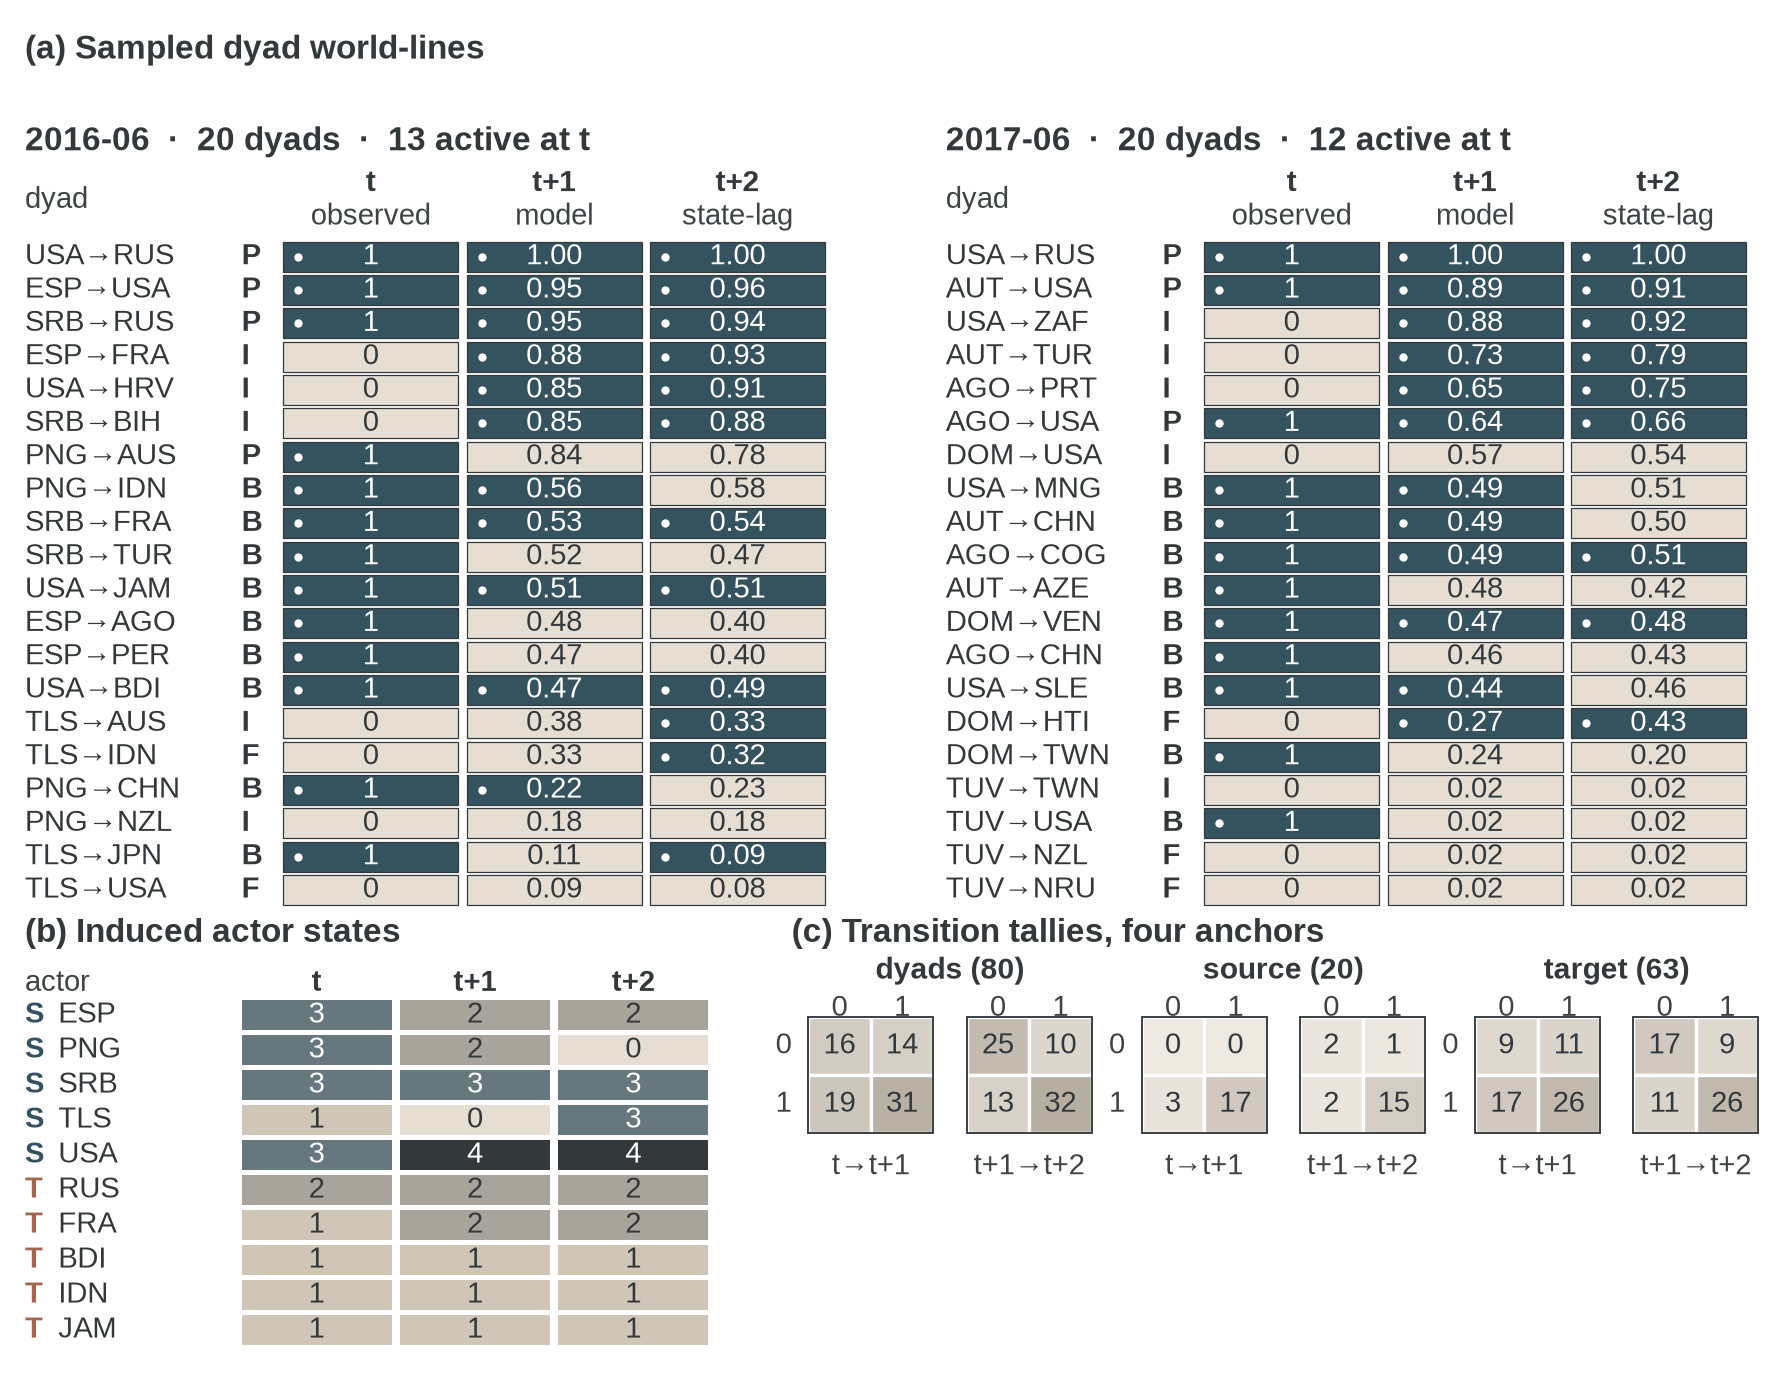

In [3]:
figure = WORLDLINE / "worldline_preview.png"

if not figure.is_file():
    print(f"[missing] {rel(figure)}")
else:
    try:
        from IPython.display import Image, display as show_image
    except Exception as exc:
        Image = None
        show_image = print
        print(f"[note] IPython display unavailable: {exc}")

    if Image is not None:
        show_image(Image(filename=str(figure)))
    else:
        print(f"Figure available at {rel(figure)}")


## Per-anchor transition tallies

**No per-row export ships.** The public tree carries the rendered figure and the
per-anchor and aggregate summaries in `worldline_trace.json`; the row-level
`worldline_trace.csv` / `node_trace.csv` files are withheld. Step 0 is the
observed anchor state; steps 1–2 are the sampled path. Counts are over the
20-dyad visibility sample per anchor and support no prevalence inference.


In [4]:
if meta:
    records = []
    for anchor in meta.get("anchors", []):
        for step, counts in anchor.get("dyad_transitions", {}).items():
            records.append(
                {"anchor": anchor["anchor"], "step": step, **counts}
            )
    if records:
        dtab = pd.DataFrame(records)
        display(dtab)
    else:
        print("Per-anchor transition tallies not available.")
else:
    print("World-line metadata not available.")


,anchor,step,00,01,10,11
0,2016-06,step1,4,3,5,8
1,2016-06,step2,6,3,2,9
2,2016-12,step1,4,4,5,7
3,2016-12,step2,6,3,4,7
4,2017-06,step1,4,4,4,8
5,2017-06,step2,8,0,3,9
6,2017-09,step1,4,3,5,8
7,2017-09,step2,5,4,4,7


## Aggregate transitions

Counts of dyad and induced-actor state transitions (00, 01, 10, 11) over the sampled subset. These are descriptive counts for the preview, not estimated transition rates.


In [5]:
if meta:
    records = []
    for unit, steps in meta.get("aggregate_transitions", {}).items():
        for step, counts in steps.items():
            for transition, n in counts.items():
                records.append(
                    {
                        "unit": unit,
                        "step": step,
                        "transition": transition,
                        "n": n,
                    }
                )
    if records:
        ttab = (
            pd.DataFrame(records)
            .pivot(index=["unit", "step"], columns="transition", values="n")
            .reset_index()
        )
        display(ttab)
    else:
        print("Aggregate transitions not available.")
else:
    print("World-line metadata not available.")


transition,unit,step,00,01,10,11
0,dyad,step1,16,14,19,31
1,dyad,step2,25,10,13,32
2,source,step1,0,0,3,17
3,source,step2,2,1,2,15
4,target,step1,9,11,17,26
5,target,step2,17,9,11,26


## Induced actor states (aggregate only)

`active` means the actor has at least one active sampled dyad. The counts below
are within the 20-dyad sample, not full-network activity; the row-level node
export is withheld. These are explanation-side projections, not node-level
forecasts.


In [6]:
if meta:
    anchor = next(
        (a for a in meta.get("anchors", []) if a["anchor"] == "2016-06"), {}
    )
    records = []
    for role, steps in anchor.get("node_transitions", {}).items():
        for step, counts in steps.items():
            records.append({"role": role, "step": step, **counts})
    if records:
        display(pd.DataFrame(records))
    else:
        print("Node transition tallies not available.")
else:
    print("World-line metadata not available.")


,role,step,00,01,10,11
0,source,step1,0,0,1,4
1,source,step2,0,1,1,3
2,target,step1,1,2,5,7
3,target,step2,4,2,1,8


## What this does not show

- No accuracy, calibration, or multi-step validation.
- No random sample and no prevalence inference.
- No uncertainty over sampled paths; the preview is one path per anchor.
- No generative update of graph, reverse-dyad, actor-ego, or train-only features at step 2; those are frozen at the anchor.
- No node-level forecast claim. Actor states are induced by the sampled dyad subset only.

A validated rolling claim would need an intermediate-month feature-generating model, out-of-sample scoring at h = 1, 2, …, paired cluster-bootstrap intervals, and a pre-registered error-accumulation stopping rule. None of that is present here.
